
# Mutual Information for Feature Ranking

Using **mutual information (MI)** to rank features and visualize results.

- builds a small example dataset
- computes mutual information scores
- ranks features by importance
- draws clean feature-importance plots
- interprets MI scores correctly

---

## Why mutual information?

Mutual information measures **how much knowing a feature reduces uncertainty about the target**.

It is useful because it can capture:

- **linear relationships**
- **non-linear relationships**
- relationships that simple correlation may miss

A higher MI score means the feature contains more information about the target.



## 1. Imports


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Make plots a bit cleaner
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

rng = np.random.RandomState(42)



## 2. Create a toy dataset

We will build a binary classification dataset with:

- one **linear** signal
- one **non-linear** signal
- one **redundant** feature
- two mostly noisy features

This makes MI useful, because it can detect both linear and non-linear signal.


In [ ]:

n = 800

x_linear = rng.normal(0, 1, n)
x_nonlinear = rng.uniform(-3, 3, n)
x_noise = rng.normal(0, 1, n)
x_weak = rng.normal(0, 1, n)
x_redundant = x_linear + rng.normal(0, 0.15, n)

# Binary target with both linear and nonlinear structure
score = 1.6 * x_linear + 1.8 * (x_nonlinear ** 2 > 2.0).astype(float) + 0.3 * x_weak + rng.normal(0, 0.8, n)
y = (score > np.median(score)).astype(int)

X = pd.DataFrame({
    "linear_signal": x_linear,
    "nonlinear_signal": x_nonlinear,
    "redundant_linear": x_redundant,
    "weak_signal": x_weak,
    "pure_noise": x_noise,
})

X.head()


,linear_signal,nonlinear_signal,redundant_linear,weak_signal,pure_noise
0,0.496714,-1.085397,0.409174,-0.470042,-0.643518
1,-0.138264,1.973493,0.017493,0.265878,0.927840
2,0.647689,-2.777954,0.419787,-0.436720,0.057013
3,1.523030,0.577619,1.098207,-0.066133,0.268592
4,-0.234153,-1.619947,-0.301827,2.099722,1.528468



## 3. Quick visual check

Before computing MI, it helps to look at the data.

Notice that the non-linear feature may still be informative even if it does not follow a simple straight-line relationship with the target.


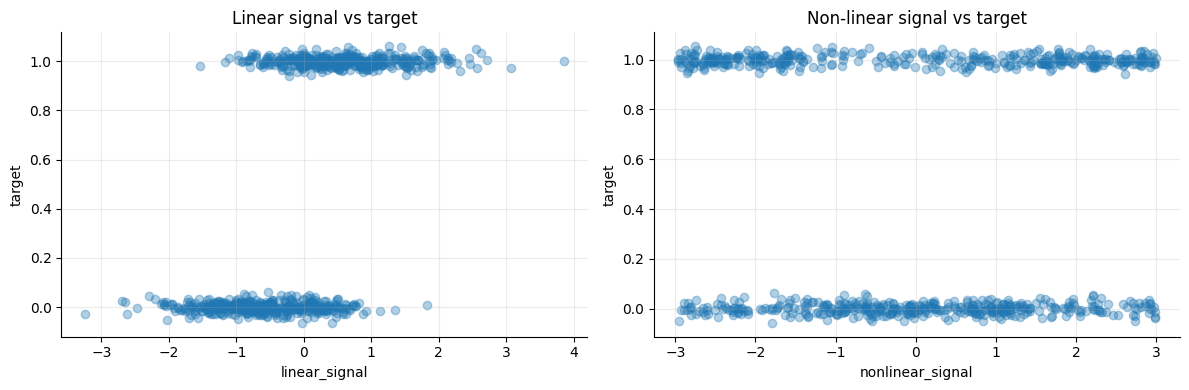

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X["linear_signal"], y + rng.normal(0, 0.02, size=len(y)), alpha=0.35)
axes[0].set_title("Linear signal vs target")
axes[0].set_xlabel("linear_signal")
axes[0].set_ylabel("target")

axes[1].scatter(X["nonlinear_signal"], y + rng.normal(0, 0.02, size=len(y)), alpha=0.35)
axes[1].set_title("Non-linear signal vs target")
axes[1].set_xlabel("nonlinear_signal")
axes[1].set_ylabel("target")

plt.tight_layout()
plt.show()



## 4. Compute mutual information scores

For a **classification** task, use `mutual_info_classif`.

Important notes:

- MI scores are **non-negative**
- larger values mean more information about the target
- MI does **not** tell you the direction of the effect
- MI scores are best used for **ranking**, not for saying one feature is exactly "twice as important"


In [ ]:

mi_scores = mutual_info_classif(
    X,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "feature": X.columns,
    "mi_score": mi_scores
}).sort_values("mi_score", ascending=False)

mi_df


,feature,mi_score
2,redundant_linear,0.243193
0,linear_signal,0.239417
1,nonlinear_signal,0.073616
3,weak_signal,0.014323
4,pure_noise,0.000000



## 5. Rank features

This table gives a simple ranking from most informative to least informative.


In [ ]:

mi_df.reset_index(drop=True, inplace=True)
mi_df.index = mi_df.index + 1
mi_df


,feature,mi_score
1,redundant_linear,0.243193
2,linear_signal,0.239417
3,nonlinear_signal,0.073616
4,weak_signal,0.014323
5,pure_noise,0.000000



## 6. Draw a clean horizontal bar plot

A horizontal bar plot is usually the clearest way to present feature rankings.


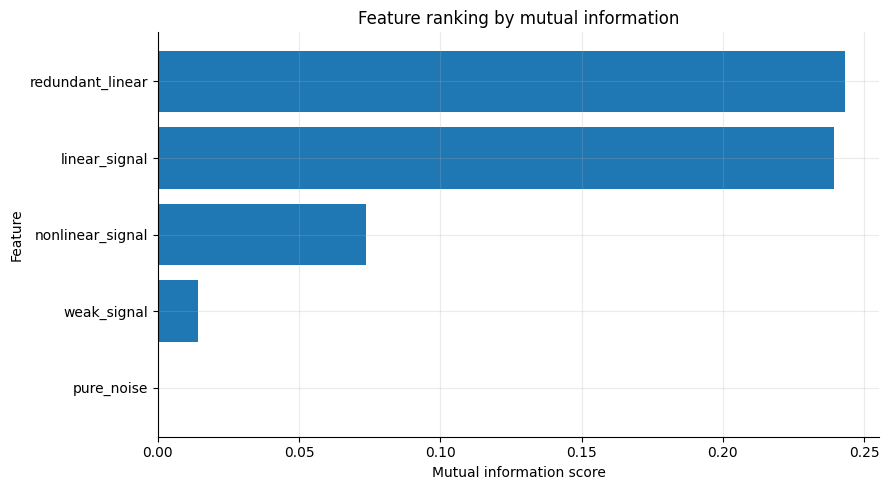

In [ ]:

plot_df = mi_df.sort_values("mi_score", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["feature"], plot_df["mi_score"])
ax.set_title("Feature ranking by mutual information")
ax.set_xlabel("Mutual information score")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()



## 7. Add value labels for presentation-ready plots

If you want a plot for slides or reports, adding labels makes it easier to read.


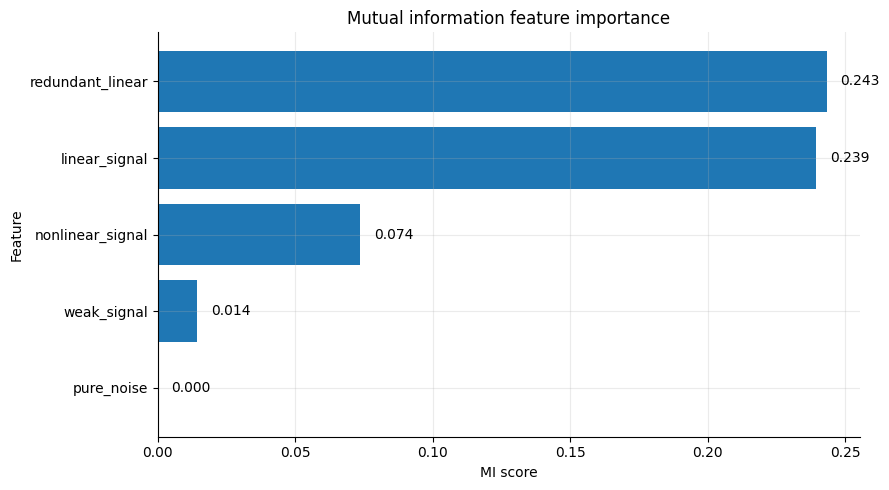

In [ ]:

plot_df = mi_df.sort_values("mi_score", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot_df["feature"], plot_df["mi_score"])

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.005, bar.get_y() + bar.get_height()/2, f"{width:.3f}", va="center")

ax.set_title("Mutual information feature importance")
ax.set_xlabel("MI score")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()



## 8. Compare MI with correlation

This is a useful teaching step.

Correlation captures mostly **linear** relationships, while MI can also capture **non-linear** signal.


In [ ]:

corr_with_target = X.assign(target=y).corr(numeric_only=True)["target"].drop("target").abs().sort_values(ascending=False)

comparison_df = (
    mi_df.set_index("feature")
    .join(corr_with_target.rename("abs_correlation"))
    .sort_values("mi_score", ascending=False)
)

comparison_df


,mi_score,abs_correlation
feature,,
redundant_linear,0.243193,0.609260
linear_signal,0.239417,0.616022
nonlinear_signal,0.073616,0.017309
weak_signal,0.014323,0.080550
pure_noise,0.000000,0.019238


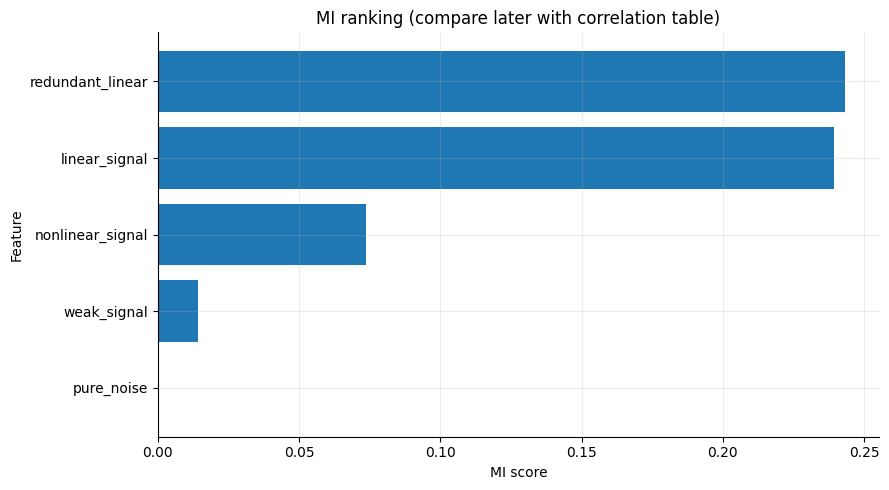

Absolute correlation with target:


,mi_score,abs_correlation
feature,,
linear_signal,0.239417,0.616022
redundant_linear,0.243193,0.609260
weak_signal,0.014323,0.080550
pure_noise,0.000000,0.019238
nonlinear_signal,0.073616,0.017309


In [ ]:

comparison_plot = comparison_df.sort_values("mi_score", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(comparison_plot.index, comparison_plot["mi_score"])
ax.set_title("MI ranking (compare later with correlation table)")
ax.set_xlabel("MI score")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

print("Absolute correlation with target:")
display(comparison_df.sort_values("abs_correlation", ascending=False))



### Interpretation

If a feature has:

- **high MI and high correlation** → likely a strong linear signal
- **high MI but lower correlation** → possibly a useful non-linear signal
- **very low MI** → likely weak or noisy for this target

In this example, `nonlinear_signal` should often rank well by MI even if its linear correlation is modest.



## 9. Optional: keep only the top-k features

A common workflow is:

1. rank features with MI
2. keep the top features
3. train a model on the reduced feature set


In [ ]:

top_k = 3
top_features = mi_df["feature"].head(top_k).tolist()
top_features


['redundant_linear', 'linear_signal', 'nonlinear_signal']

In [ ]:

X_top = X[top_features]
X_top.head()


,redundant_linear,linear_signal,nonlinear_signal
0,0.409174,0.496714,-1.085397
1,0.017493,-0.138264,1.973493
2,0.419787,0.647689,-2.777954
3,1.098207,1.523030,0.577619
4,-0.301827,-0.234153,-1.619947



## 10. A reusable helper function

This function makes it easy to compute MI, return a ranking table, and draw a clean plot for any classification dataset.


In [ ]:

def rank_features_with_mi(X, y, random_state=42, figsize=(9, 5)):
    scores = mutual_info_classif(X, y, random_state=random_state)
    result = (
        pd.DataFrame({"feature": X.columns, "mi_score": scores})
        .sort_values("mi_score", ascending=False)
        .reset_index(drop=True)
    )

    plot_df = result.sort_values("mi_score", ascending=True)

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(plot_df["feature"], plot_df["mi_score"])

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.005, bar.get_y() + bar.get_height()/2, f"{width:.3f}", va="center")

    ax.set_title("Feature ranking by mutual information")
    ax.set_xlabel("MI score")
    ax.set_ylabel("Feature")
    plt.tight_layout()
    plt.show()

    return result


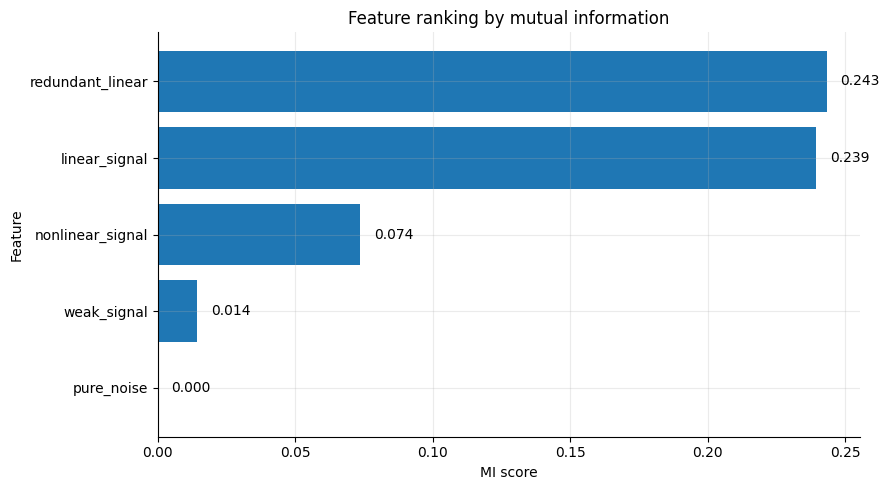

,feature,mi_score
0,redundant_linear,0.243193
1,linear_signal,0.239417
2,nonlinear_signal,0.073616
3,weak_signal,0.014323
4,pure_noise,0.000000


In [ ]:

ranked_features = rank_features_with_mi(X, y)
ranked_features



## 11. Practical tips

When using MI in real projects:

- use it mainly for **ranking**
- do not over-interpret small score differences
- remember that MI does **not** show whether the effect is positive or negative
- MI evaluates features **individually**, so it may miss interactions
- for continuous features, MI estimation depends on the estimator and data sample
- combine MI with model-based or post-hoc methods if needed

MI is a strong baseline for **filter-based feature importance**, especially when relationships may be non-linear.
